<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Count measured waves before counting exceedances

**How much does the denominator change a wave-threshold summary?** NOAA's recent
Boston buoy file contains weather rows with and without wave measurements. Retrieve
those rows through VGI, audit availability, then compare the fraction of measured
wave heights above a chosen threshold with the fraction of *all returned rows*.

**Recorded official data, real worker.** The default replays unchanged NOAA NDBC
responses captured on **14 November 2026 UTC** through the published worker's
supported base-URL override. These are public source recordings, not synthetic waves.
A separate live mode uses NOAA directly with a recent window and no fallback.

The quantity is **significant wave height**, in metres: an average of the highest
one-third of waves in a sampling period, not the largest individual wave.
[NOAA measurement definitions](https://www.ndbc.noaa.gov/measdes.shtml) and the
[Boston station page](https://www.ndbc.noaa.gov/station_page.php?station=44013)
provide context. The threshold below is an analytical choice, not a safety boundary.

## Choose the threshold

`WAVE_THRESHOLD_M` is finite, greater than zero and at most **20 metres**; default
**2.0**, experiment **3.0**. An exceedance here means **greater than or equal to**
the threshold. `DATA_MODE` is **"recorded"** or **"live"**. Restart and run all after edits.

Station **44013** and a **48-hour** duration are fixed. Recorded mode uses
**12 November 2026 06:00 UTC inclusive → 14 November 2026 06:00 UTC exclusive**,
the capture hour rounded down. Live mode uses the 48 hours before the current UTC
minute. It does not shift its window to fit stale observations.

In [1]:
WAVE_THRESHOLD_M = 2.0  # Significant wave height, metres; experiment 3.0
DATA_MODE = "recorded"  # "recorded" or "live"; no fallback

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

replay, previous_env, run_at, provenance, start_iso, end_iso = configure(WAVE_THRESHOLD_M, DATA_MODE)
start_arg, end_arg = start_iso.replace("+00:00", "Z"), end_iso.replace("+00:00", "Z")
source = f"Source: NOAA NDBC · station 44013 · {provenance}"
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-buoys-portable-xpi3382l/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-buoys-portable-xpi3382l/pyproject.toml.

## Attach the published release and verify units

The literal location selects native release **v0.1.0**, source revision
`6d34f79eeb80d31bdb188666f60d116204625bb8`. Haybarn downloads the platform asset;
no parent checkout or local worker build is needed. The setup helper uses the
worker's supported `BUOYS_BASE_URL` only for recorded mode and removes inherited
overrides in live mode.

Read the worker's local measurement reference first. A missing `MM` becomes NULL
before any unit conversion. A measured zero remains zero.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL icu;
LOAD icu;
SET TimeZone = 'UTC';
ATTACH 'buoys' AS buoys (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-buoys@v0.1.0');
CREATE TABLE units AS SELECT * FROM buoys.main.measurements;
SELECT column_name, source_field, source_unit, output_unit, scale
FROM units
WHERE column_name IN ('wave_height_m', 'wind_speed_mps', 'visibility_m', 'water_level_m')
ORDER BY column_name;

,column_name,source_field,source_unit,output_unit,scale
0,visibility_m,VIS,nmi,m,1852.0000
1,water_level_m,TIDE,ft,m,0.3048
2,wave_height_m,WVHT,m,m,1.0000
3,wind_speed_mps,WSPD,m/s,m/s,1.0000


## Retrieve each response once

Materialize the station directory and history before capturing DataFrames, so
charting and comparisons do not repeat network calls. History bounds are inclusive
in the worker; a second SQL filter below makes our analysis end **exclusive**.
This downloads a recent file and filters it; it does not fetch historical archives.
Station coordinates come from the directory, not from the fixed-station history.

`fetched_at` is when the worker processes this response. In recorded mode that is
replay time, and `source_url` is loopback. Original URLs and capture timestamps are
separately preserved in [the recording manifest](recordings/manifest.json).

In [4]:
%%sql
CREATE TABLE settings AS SELECT
    '{{start_iso}}'::TIMESTAMPTZ AS window_start,
    '{{end_iso}}'::TIMESTAMPTZ AS window_end,
    {{WAVE_THRESHOLD_M}}::DOUBLE AS threshold_m;
CREATE TABLE directory AS SELECT * FROM buoys.main.stations();
CREATE TABLE fetched_history AS
SELECT * FROM buoys.main.observations('44013', start_time := '{{start_arg}}', end_time := '{{end_arg}}');
CREATE TABLE observations AS
SELECT h.* FROM fetched_history h CROSS JOIN settings s
WHERE h.time >= s.window_start AND h.time < s.window_end;
SELECT station_id, name, latitude, longitude, owner, has_met
FROM directory WHERE station_id = '44013';

,station_id,name,latitude,longitude,owner,has_met
0,44013,"BOSTON 16 NM East of Boston, MA",42.346,-70.651,NDBC,True


In [5]:
%%sql quality <<
WITH gaps AS (
  SELECT time, wave_height_m, time - lag(time) OVER (ORDER BY time) AS row_gap
  FROM observations
)
SELECT count(*) AS returned_rows, count(DISTINCT time) AS unique_times,
       count(wave_height_m) AS measured_waves,
       count(*) FILTER (WHERE wave_height_m IS NULL) AS missing_waves,
       count(*) FILTER (WHERE wave_height_m = 0) AS measured_zeroes,
       min(time) AS first_time, max(time) AS last_time,
       max(row_gap) AS largest_row_gap,
       (SELECT window_end FROM settings) - max(time) AS lag_from_window_end,
       (SELECT min(fetched_at) FROM fetched_history) AS worker_fetched_at,
       (SELECT min(source_url) FROM fetched_history) AS worker_source_url
FROM gaps;

In [6]:
display(quality)
q = quality.iloc[0]
if q.returned_rows == 0:
    raise ValueError("No observations in the requested window; check source availability and freshness")
if q.measured_waves == 0:
    raise ValueError("Rows exist, but no measured wave heights support a threshold fraction")
if q.unique_times != q.returned_rows:
    raise ValueError("Duplicate timestamps need investigation before calculating row fractions")
prose(
    f"**{q.measured_waves:,} of {q.returned_rows:,} returned rows have a wave height** "
    f"({100 * q.measured_waves / q.returned_rows:.1f}% coverage); {q.missing_waves:,} do not. "
    f"There are {q.measured_zeroes:,} measured zeroes. The newest row is **{q.lag_from_window_end}** "
    f"before the window end; the largest gap between returned rows is **{q.largest_row_gap}**. "
    "These are availability diagnostics, not a count of instrument failures. "
    "There is no assumed reporting schedule and no fabricated row for an absent timestamp."
)
prose(
    f"**{provenance}.** Run started `{run_at}`. Window: `{start_iso}` inclusive to `{end_iso}` exclusive. "
    "Independent directory and history responses are not an atomic snapshot."
)

,returned_rows,unique_times,measured_waves,missing_waves,measured_zeroes,first_time,last_time,largest_row_gap,lag_from_window_end,worker_fetched_at,worker_source_url
0,281,281,135,146,0,2026-11-12 01:00:00-05:00,2026-11-14 00:10:00-05:00,0 days 00:30:00,0 days 00:50:00,2026-11-14 01:07:04.797000-05:00,http://127.0.0.1:58508/data/realtime2/44013.txt


**135 of 281 returned rows have a wave height** (48.0% coverage); 146 do not. There are 0 measured zeroes. The newest row is **0 days 00:50:00** before the window end; the largest gap between returned rows is **0 days 00:30:00**. These are availability diagnostics, not a count of instrument failures. There is no assumed reporting schedule and no fabricated row for an absent timestamp.

**Recorded NOAA responses · captured 2026-11-14 06:02 UTC.** Run started `2026-11-14T06:07:04.335441+00:00`. Window: `2026-11-12T06:00:00+00:00` inclusive to `2026-11-14T06:00:00+00:00` exclusive. Independent directory and history responses are not an atomic snapshot.

## Classify observed, below-threshold and unmeasured rows

Keep NULL as a separate category. The measured-wave denominator excludes NULL;
the all-row denominator includes it. Their numerators are identical. The latter
can be useful as a reporting statistic, but it must not be described as the
fraction of *measured waves* above the threshold. Neither denominator measures time.

In [7]:
%%sql
CREATE TABLE classified AS
SELECT o.*, CASE WHEN wave_height_m IS NULL THEN 'No wave measurement'
                 WHEN wave_height_m >= threshold_m THEN 'At or above threshold'
                 ELSE 'Below threshold' END AS wave_class
FROM observations o CROSS JOIN settings;
CREATE TABLE summary AS
SELECT count(*) AS all_rows, count(wave_height_m) AS measured_rows,
       count(*) FILTER (WHERE wave_class = 'At or above threshold') AS exceedances,
       count(*) FILTER (WHERE wave_class = 'Below threshold') AS below_threshold,
       count(*) FILTER (WHERE wave_class = 'No wave measurement') AS unmeasured,
       min(wave_height_m) AS minimum_m, max(wave_height_m) AS maximum_m
FROM classified;
CREATE TABLE fractions AS
SELECT 'Measured wave rows' AS denominator, measured_rows AS denominator_rows,
       exceedances, below_threshold, 0::BIGINT AS unmeasured,
       100.0 * exceedances / measured_rows AS exceedance_pct
FROM summary
UNION ALL
SELECT 'All returned weather rows', all_rows, exceedances, below_threshold, unmeasured,
       100.0 * exceedances / all_rows FROM summary;
SELECT denominator, denominator_rows, exceedances,
       round(exceedance_pct, 2) AS exceedance_pct, unmeasured
FROM fractions ORDER BY denominator_rows;

,denominator,denominator_rows,exceedances,exceedance_pct,unmeasured
0,Measured wave rows,135,53,39.26,0
1,All returned weather rows,281,53,18.86,146


In [8]:
%%sql summary_frame <<
SELECT * FROM summary;

In [9]:
%%sql fractions_frame <<
SELECT * FROM fractions ORDER BY denominator_rows;

In [10]:
s = summary_frame.iloc[0]
measured_pct = 100 * s.exceedances / s.measured_rows
all_pct = 100 * s.exceedances / s.all_rows
prose(
    f"At **{WAVE_THRESHOLD_M:g} m**, **{s.exceedances:,.0f} of {s.measured_rows:,.0f} measured wave rows** "
    f"meet the threshold: **{measured_pct:.2f}%**. The same count divided by all "
    f"{s.all_rows:,.0f} weather rows is **{all_pct:.2f}%**, a difference of "
    f"**{measured_pct - all_pct:.2f} percentage points**. "
    f"Observed wave heights span {s.minimum_m:.1f}–{s.maximum_m:.1f} m. "
    "The denominator changes the question; it provides no evidence that unmeasured waves "
    "were below the threshold."
)

At **2 m**, **53 of 135 measured wave rows** meet the threshold: **39.26%**. The same count divided by all 281 weather rows is **18.86%**, a difference of **20.40 percentage points**. Observed wave heights span 0.3–3.0 m. The denominator changes the question; it provides no evidence that unmeasured waves were below the threshold.

## Look at measurements and availability together

Dots are returned wave measurements; points are not connected across gaps. The
lower panel counts the three row categories per UTC hour, including partial edge
hours. It shows reporting density, not an expected hourly quota. Shared time axes
keep the wave measurements and availability aligned.

In [11]:
%%sql wave_frame <<
SELECT time, wave_height_m, wave_class FROM classified ORDER BY time;

In [12]:
%%sql hourly_frame <<
SELECT date_trunc('hour', time) AS hour,
       count(*) FILTER (WHERE wave_class = 'Below threshold') AS below_threshold,
       count(*) FILTER (WHERE wave_class = 'At or above threshold') AS exceedances,
       count(*) FILTER (WHERE wave_class = 'No wave measurement') AS unmeasured
FROM classified GROUP BY hour ORDER BY hour;

findfont: Failed to find font weight semibold for Arial, now using 700.


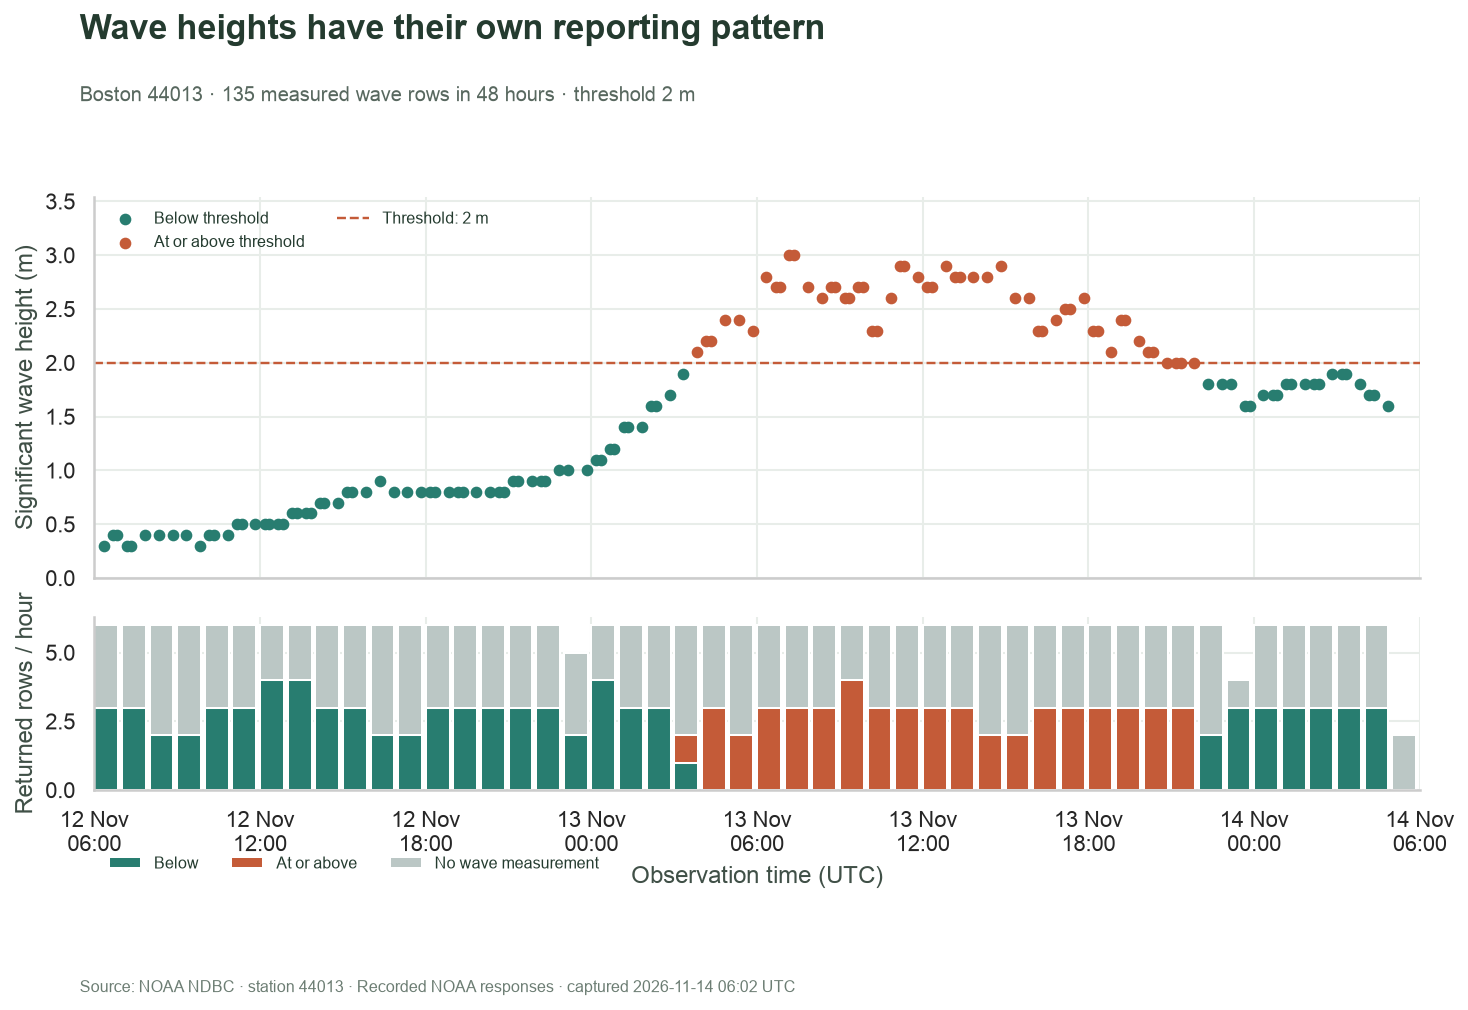

In [13]:
green, red, grey = "#287D70", "#C45B38", "#BBC7C5"
fig, axes = plt.subplots(2, 1, figsize=(10.5, 7.1), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
w = wave_frame.copy()
w["time"] = pd.to_datetime(w["time"], utc=True)
for label, color in [("Below threshold", green), ("At or above threshold", red)]:
    part = w[w.wave_class == label]
    axes[0].scatter(part.time, part.wave_height_m, s=23, color=color, label=label, zorder=3)
axes[0].axhline(
    WAVE_THRESHOLD_M, color=red, linestyle="--", linewidth=1.2, label=f"Threshold: {WAVE_THRESHOLD_M:g} m"
)
axes[0].set(ylabel="Significant wave height (m)", ylim=(0, max(WAVE_THRESHOLD_M, s.maximum_m) * 1.18))
axes[0].legend(loc="upper left", ncol=2, fontsize=8)
h = hourly_frame.copy()
h["hour"] = pd.to_datetime(h["hour"], utc=True)
bottom = pd.Series(0, index=h.index)
for col, label, color in [
    ("below_threshold", "Below", green),
    ("exceedances", "At or above", red),
    ("unmeasured", "No wave measurement", grey),
]:
    axes[1].bar(h.hour, h[col], width=0.036, bottom=bottom, color=color, label=label, align="edge")
    bottom += h[col]
axes[1].set(
    ylabel="Returned rows / hour",
    xlabel="Observation time (UTC)",
    xlim=(pd.Timestamp(start_iso), pd.Timestamp(end_iso)),
)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M", tz="UTC"))
axes[1].legend(loc="upper left", bbox_to_anchor=(0, -0.3), ncol=3, fontsize=8)
chart(
    fig,
    "Wave heights have their own reporting pattern",
    f"Boston 44013 · {s.measured_rows:,.0f} measured wave rows in 48 hours · "
    f"threshold {WAVE_THRESHOLD_M:g} m",
    source,
)

## Show exactly what each denominator includes

The two bars normalize the same observed categories to different totals. Grey
represents unmeasured waves and is retained in the all-row bar. A smaller red share
there does not make the sea state calmer. Counts in the labels expose the change
in denominator; the horizontal axis uses the same 0–100% scale for both bars.

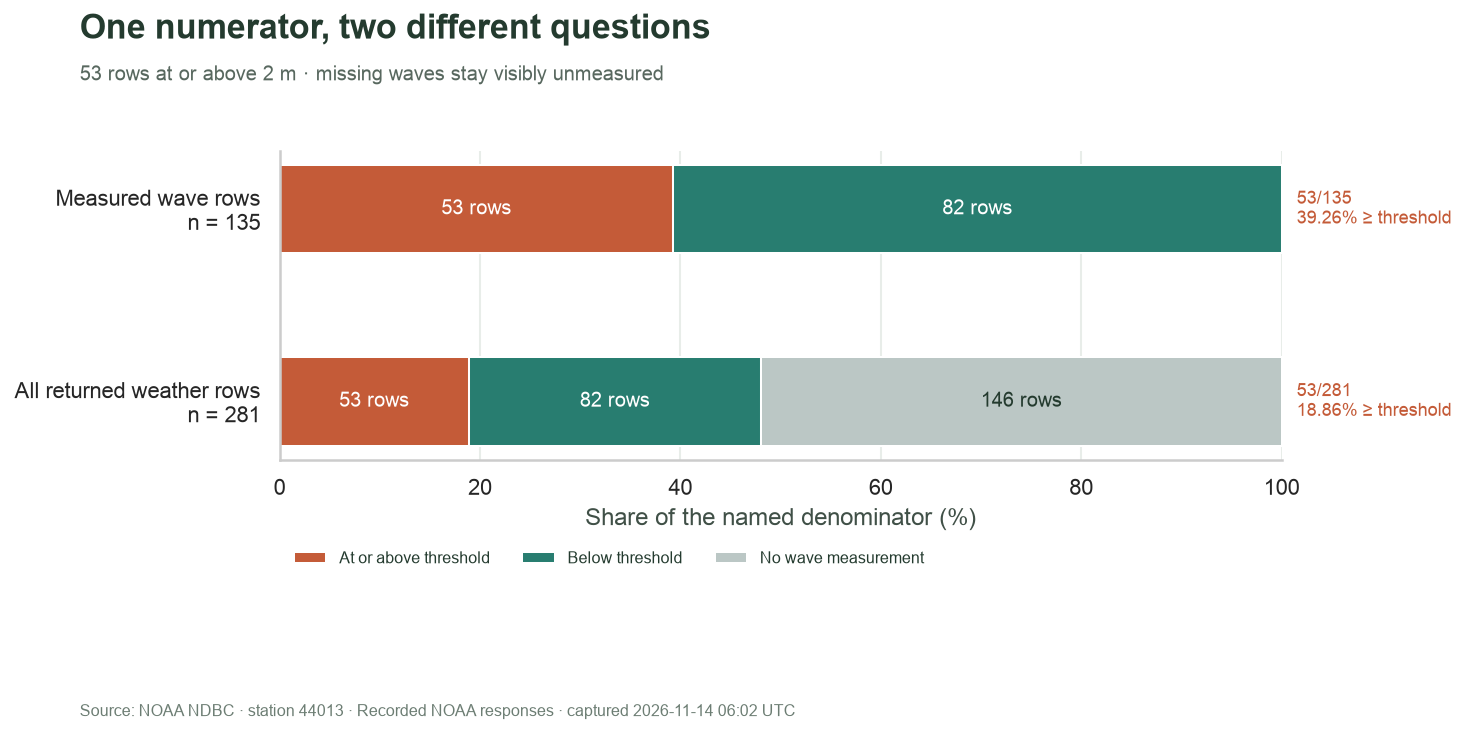

In [14]:
fig, ax = plt.subplots(figsize=(10.5, 5.1))
f = fractions_frame.copy()
labels = [f"{r.denominator}\nn = {r.denominator_rows:,}" for r in f.itertuples()]
left = pd.Series(0.0, index=f.index)
for col, label, color in [
    ("exceedances", "At or above threshold", red),
    ("below_threshold", "Below threshold", green),
    ("unmeasured", "No wave measurement", grey),
]:
    pct = 100 * f[col] / f.denominator_rows
    ax.barh(labels, pct, left=left, height=0.46, color=color, label=label)
    for i, (amount, offset, count) in enumerate(zip(pct, left, f[col], strict=True)):
        if amount >= 10:
            ax.text(
                offset + amount / 2,
                i,
                f"{count:,} rows",
                ha="center",
                va="center",
                color="#243B2F" if col == "unmeasured" else "white",
                fontsize=10,
            )
    left += pct
for i, r in enumerate(f.itertuples()):
    ax.text(
        101.5,
        i,
        f"{r.exceedances:,}/{r.denominator_rows:,}\n{r.exceedance_pct:.2f}% ≥ threshold",
        va="center",
        fontsize=9,
        color=red,
    )
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Share of the named denominator (%)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.25), ncol=3, fontsize=8)
ax.grid(axis="y", visible=False)
chart(
    fig,
    "One numerator, two different questions",
    f"{s.exceedances:,.0f} rows at or above {WAVE_THRESHOLD_M:g} m · missing waves stay visibly unmeasured",
    source,
)

## Check the identities behind the comparison

Validate the relationships, not a hardcoded count or outcome. The all-row
exceedance fraction must equal the measured-wave fraction multiplied by wave
coverage. The three categories partition returned rows, and increasing a threshold
cannot add exceedances on the same data. These checks validate the calculation;
they do not validate NOAA sensor accuracy or infer unobserved wave heights.

In [15]:
%%sql checks <<
SELECT 'One row per station and time' AS check_name,
       count(*) = count(DISTINCT (station_id, time)) AS passed FROM classified
UNION ALL SELECT 'Half-open UTC window', bool_and(time >= window_start AND time < window_end)
  FROM classified CROSS JOIN settings
UNION ALL SELECT 'Nonnegative finite measured heights',
  bool_and(wave_height_m IS NULL OR (isfinite(wave_height_m) AND wave_height_m >= 0)) FROM classified
UNION ALL SELECT 'Categories partition all rows',
  exceedances + below_threshold + unmeasured = all_rows FROM summary
UNION ALL SELECT 'Measured denominator excludes NULL',
  exceedances + below_threshold = measured_rows AND measured_rows + unmeasured = all_rows FROM summary
UNION ALL SELECT 'Denominator identity',
  abs(1.0*exceedances/all_rows - (1.0*exceedances/measured_rows)*(1.0*measured_rows/all_rows)) < 1e-12
  FROM summary
UNION ALL SELECT 'Higher threshold cannot add exceedances',
  count(*) FILTER (WHERE wave_height_m >= threshold_m + 1) <=
  count(*) FILTER (WHERE wave_height_m >= threshold_m) FROM classified CROSS JOIN settings
UNION ALL SELECT 'Wave units remain metres without rescaling',
  count(*) = 1 AND bool_and(source_unit = 'm' AND output_unit = 'm' AND scale = 1)
  FROM units WHERE column_name = 'wave_height_m'
UNION ALL SELECT 'Boston station metadata is unique',
  count(*) = 1 FROM directory WHERE station_id = '44013';

In [16]:
display(checks)
assert checks.passed.fillna(False).all(), "A SQL invariant failed; inspect the table above"
if replay:
    assert sorted(replay.requests) == ["/activestations.xml", "/data/realtime2/44013.txt"], replay.requests
prose(
    f"**All {len(checks)} SQL checks passed.** "
    + (
        "The replay server saw exactly one directory and one history request. "
        if replay
        else "Live NOAA responses were materialized before analysis. "
    )
    + "The sample is one station and one short window. Fractions count returned measurements, "
    "not individual ocean waves or elapsed time. Missingness may be systematic; "
    "these results alone do not support extrapolation or a storm forecast."
)

,check_name,passed
0,One row per station and time,True
1,Half-open UTC window,True
2,Nonnegative finite measured heights,True
3,Categories partition all rows,True
4,Measured denominator excludes NULL,True
5,Denominator identity,True
6,Higher threshold cannot add exceedances,True
7,Wave units remain metres without rescaling,True
8,Boston station metadata is unique,True


**All 9 SQL checks passed.** The replay server saw exactly one directory and one history request. The sample is one station and one short window. Fractions count returned measurements, not individual ocean waves or elapsed time. Missingness may be systematic; these results alone do not support extrapolation or a storm forecast.

## Experiment · raise only the threshold

Keep recorded mode and change **WAVE_THRESHOLD_M from 2.0 to 3.0 metres**. Predict
that exceedance counts cannot increase, while the measured-row and all-row
denominators remain unchanged. Compare the red points, the two labelled fractions
and the missing-wave count. Reset to **2.0** afterward.

```sh
uv run --locked python execute.py --timeout 300 \
  --parameters '{"WAVE_THRESHOLD_M": 3.0}' --output-dir artifacts/threshold-3m
```

The runner keeps the successful default intact and copies its companions beside
the experiment. Threshold choice changes the statistic, not the underlying sea
state. Live mode is a separate check with a moving window; it cannot isolate the
threshold effect as cleanly as these fixed recordings.

In [17]:
con.close()
cleanup(replay, previous_env)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)